In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
import time
from typing import Callable, Dict, List, Tuple, Optional, Set

### Data Files Definition For Easier Loading

In [3]:
DATA_DIR = Path("data")

TRAIN = DATA_DIR / "train.csv"
VAL  = DATA_DIR / "validation.csv"
TEST = DATA_DIR / "test.csv"
EVALUATION = DATA_DIR / "evaluation.csv"
TRAIN_TRIPLETS = DATA_DIR / "train_triplets.csv"
VAL_TRIPLETS = DATA_DIR / "validation_triplets.csv"
CATALOG = DATA_DIR / "products.csv"
PRODUCT_FEATURES = DATA_DIR / "product_features.npz"

### Loading the Products, ie the catalog

In [4]:
def load_products(path: Path) -> pd.DataFrame:
    product = pd.read_csv(path)
    assert "product_id" in product.columns, "products.csv must have a 'product_id' column"
    assert "catalog" in product.columns, "products.csv must have a 'catalog' column"

    product = product.sort_values("product_id").reset_index(drop=True)
    print(f"[catalog] {len(product)} products loaded")
    print(product["catalog"].value_counts().to_string())
    
    return product

def load_val_test(path: Path, split_name: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    expected = {"user_id", "product_id", "rating", "timestamp"}
    assert expected.issubset(df.columns), \
        f"{path.name} missing columns: {expected - set(df.columns)}"
    print(f"\n[{split_name}] raw rows: {len(df)}")
    return df

def load_triplets(path: Path, split_name: str, all_item_ids: set) -> pd.DataFrame:
    df = pd.read_csv(path)
    expected = {"user_id", "positive_id", "comparison_id"}
    assert expected.issubset(df.columns), \
        f"{path.name} missing columns: {expected - set(df.columns)}"

    before = len(df)
    mask = df["positive_id"].isin(all_item_ids) & df["comparison_id"].isin(all_item_ids)
    df = df[mask].reset_index(drop=True)
    dropped = before - len(df)
    if dropped:
        print(f"[{split_name} triplets] dropped {dropped} triplets with unknown IDs")
    else:
        print(f"[{split_name} triplets] all IDs in catalog ({len(df)} triplets)")
    return df

def load_product_features(path: Path) -> np.ndarray:
    #.npz files are archives; we try the key 'features' first, then fall back to the first key found in the archive.
    archive = np.load(path)
    if "Z" in archive:
        Z = archive["Z"]
    elif "features" in archive:
        Z = archive["features"]
    else:
        key = list(archive.keys())[0]
        print(f"[text features] unexpected key '{key}' — using it")
        Z = archive[key]

    assert Z.ndim == 2 and Z.shape[1] == 384, \
        f"Expected shape (num_products, 384), got {Z.shape}"
    print(f"\n[text features] shape: {Z.shape}")
    # check: vectors should be (approximately) unit length
    norms = np.linalg.norm(Z, axis=1)
    print(f"[text features] norm min={norms.min():.4f}, max={norms.max():.4f} "
          f"(should be ≈ 1.0)")
    return Z

Since the data explorer shows IDs are already zero-based integers,the maps are functions over the valid ranges.
We still build explicit sets/dicts so downstream code is safe if the actual CSVs use arbitrary IDs.

### Safe Filtering for Products

In [5]:
def safe_filter(
    df: pd.DataFrame,
    all_item_ids: set,
    split_name: str
) -> pd.DataFrame:
    
    #Drop any row whose product_id is not in the products.
    before = len(df)
    df = df[df["product_id"].isin(all_item_ids)].reset_index(drop=True)
    dropped = before - len(df)
    if dropped:
        print(f"[{split_name}] dropped {dropped} rows with unknown product_ids")
    else:
        print(f"[{split_name}] all product_ids are in catalog")
    return df


### ID Mapping

In [6]:
def build_id_maps(product: pd.DataFrame):
    all_item_ids = set(product["product_id"])
    ordinary_item_ids = set(product.loc[product["catalog"] == "ordinary", "product_id"])
    cold_val_ids = set(product.loc[product["catalog"] == "cold_validation", "product_id"])
    cold_test_ids = set(product.loc[product["catalog"] == "cold_test", "product_id"])

    # Map product_id -> integer index (row in features / factor matrices)
    item_id_to_idx = {pid: idx for idx, pid in enumerate(product["product_id"])}

    print(f"\n[id maps] ordinary={len(ordinary_item_ids)}, "
          f"cold_val={len(cold_val_ids)}, cold_test={len(cold_test_ids)}, "
          f"total={len(all_item_ids)}")

    return ordinary_item_ids, all_item_ids, cold_val_ids, cold_test_ids, item_id_to_idx

def apply_id_maps(
    df: pd.DataFrame,
    item_id_to_idx: dict,
    split_name: str
) -> pd.DataFrame:
    """
    Add 'item_idx' column: the integer index into factor matrices / feature arrays.
    user_id is already 0-based so we keep it as-is (rename for clarity).
    Rows with unmapped IDs (users or items not seen in catalog) are dropped.
    """
    df = df.copy()

    # Map product_id → item_idx
    df["item_idx"] = df["product_id"].map(item_id_to_idx)

    # user_id is already a clean integer index
    df = df.rename(columns={"user_id": "user_idx"})

    # Drop any NaN - another safety measure
    before = len(df)
    df = df.dropna(subset=["user_idx", "item_idx"]).reset_index(drop=True)
    df["user_idx"] = df["user_idx"].astype(int)
    df["item_idx"] = df["item_idx"].astype(int)
    dropped = before - len(df)
    if dropped:
        print(f"[{split_name}] dropped {dropped} rows after ID mapping")

    print(f"[{split_name}] final rows: {len(df)}, "
          f"unique users: {df['user_idx'].nunique()}, "
          f"unique items: {df['item_idx'].nunique()}")
    return df

### User Positives

In [7]:
def build_user_positives(reviews: pd.DataFrame) -> dict:
    """
    Returns {user_idx: set of item_idx} for all positive interactions
    (rating >= 4) in the given split.
    Used by the Recall@10 / NDCG@10 evaluator.
    """
    pos = reviews[reviews["rating"] >= 4]
    user_positives = (
        pos.groupby("user_idx")["item_idx"]
           .apply(set)
           .to_dict()
    )
    return user_positives

### Main Run for Loading

In [8]:
def load_all_data(data_dir: Path = DATA_DIR) -> dict:
    print("PHASE 1 — DATA LOADING")

    # Products
    products = load_products(data_dir / "products.csv")
    (ordinary_ids,
     all_ids,
     cold_val_ids,
     cold_test_ids,
     item_id_to_idx) = build_id_maps(products)

    # Reviews
    val_reviews  = load_val_test(data_dir / "validation.csv",  "validation")
    test_reviews = load_val_test(data_dir / "test.csv",        "test")

    # evaluation.csv — load and peek at columns so we know what it contains
    # evaluation.csv — ground-truth relevance file for Recall@10 / NDCG@10
    # Columns: task, split, user_id, relevant_product_id
    if (data_dir / "evaluation.csv").exists():
        eval_df = pd.read_csv(data_dir / "evaluation.csv")
        print(f"\n[evaluation.csv] {len(eval_df)} rows, columns: {list(eval_df.columns)}")
        print(eval_df.groupby(["task", "split"]).size().to_string())
    else:
        eval_df = None
        print("\n[evaluation.csv] not found — skipping")

    # Catalog-safe filter
    val_reviews  = safe_filter(val_reviews,  all_ids, "validation")
    test_reviews = safe_filter(test_reviews, all_ids, "test")

    # Apply ID maps
    val_reviews  = apply_id_maps(val_reviews,  item_id_to_idx, "validation")
    test_reviews = apply_id_maps(test_reviews, item_id_to_idx, "test")

    # Triplets (validation only — no test_triplets.csv in the data folder)
    val_triplets = load_triplets(data_dir / "validation_triplets.csv",
                                 "validation", all_ids)

    # Text features
    Z = load_product_features(data_dir / "product_features.npz")

    # Per-user positive sets (for metric computation)
    val_user_positives  = build_user_positives(val_reviews)
    test_user_positives = build_user_positives(test_reviews)

    # Separate ordinary vs cold reviews (needed for cold-start evaluation later)
    val_ordinary_reviews  = val_reviews[val_reviews["item_idx"].map(
        lambda i: products.iloc[i]["catalog"] == "ordinary")]
    val_cold_reviews      = val_reviews[val_reviews["item_idx"].map(
        lambda i: products.iloc[i]["catalog"] == "cold_validation")]
    test_ordinary_reviews = test_reviews[test_reviews["item_idx"].map(
        lambda i: products.iloc[i]["catalog"] == "ordinary")]
    test_cold_reviews     = test_reviews[test_reviews["item_idx"].map(
        lambda i: products.iloc[i]["catalog"] == "cold_test")]

    print("SUMMARY")
    print(f"Users : 170")
    print(f"Ordinary items: {len(ordinary_ids)}")
    print(f"Cold-val items: {len(cold_val_ids)}")
    print(f"Cold-test items: {len(cold_test_ids)}")
    print(f"Val reviews: {len(val_reviews)}")
    print(f"ordinary: {len(val_ordinary_reviews)}")
    print(f"cold: {len(val_cold_reviews)}")
    print(f"Test reviews: {len(test_reviews)}")
    print(f"ordinary: {len(test_ordinary_reviews)}")
    print(f"cold: {len(test_cold_reviews)}")
    print(f"Val triplets: {len(val_triplets)}")
    print(f"Text feature shape : {Z.shape}")

    return {
        # catalog info
        "products":products,
        "eval_df":eval_df,          # raw evaluation.csv (inspect columns first)
        "ordinary_ids":ordinary_ids,
        "all_ids":all_ids,
        "cold_val_ids":cold_val_ids,
        "cold_test_ids":cold_test_ids,
        "item_id_to_idx":item_id_to_idx,
        "num_users":170,
        "num_items":len(products),

        # reviews
        "val_reviews":val_reviews,
        "test_reviews":test_reviews,
        "val_ordinary_reviews":val_ordinary_reviews,
        "val_cold_reviews":val_cold_reviews,
        "test_ordinary_reviews":test_ordinary_reviews,
        "test_cold_reviews":test_cold_reviews,

        # triplets
        "val_triplets":val_triplets,

        # per-user positives
        "val_user_positives":val_user_positives,
        "test_user_positives": test_user_positives,

        # text features
        "Z":Z,
    }

In [9]:
data = load_all_data()
print("\n── Validation reviews sample ──")
print(data["val_reviews"].head())

print("\n── Test reviews sample ──")
print(data["test_reviews"].head())

print("\n── Val triplets sample ──")
print(data["val_triplets"].head())

print("\n── Users with ≥1 positive in validation ──")
print(f"  {len(data['val_user_positives'])} users")

PHASE 1 — DATA LOADING
[catalog] 286 products loaded
catalog
ordinary           206
cold_validation     40
cold_test           40

[id maps] ordinary=206, cold_val=40, cold_test=40, total=286

[validation] raw rows: 358

[test] raw rows: 362

[evaluation.csv] 665 rows, columns: ['task', 'split', 'user_id', 'relevant_product_id']
task      split     
cold      test          217
          validation    217
ordinary  test          110
          validation    121
[validation] all product_ids are in catalog
[test] all product_ids are in catalog
[validation] final rows: 358, unique users: 160, unique items: 122
[test] final rows: 362, unique users: 158, unique items: 119
[validation triplets] all IDs in catalog (121 triplets)

[text features] shape: (286, 384)
[text features] norm min=1.0000, max=1.0000 (should be ≈ 1.0)
SUMMARY
Users : 170
Ordinary items: 206
Cold-val items: 40
Cold-test items: 40
Val reviews: 358
ordinary: 129
cold: 229
Test reviews: 362
ordinary: 120
cold: 242
Val triplet

### Shared Maps

In [10]:
ordinary_ids_sorted = sorted(data["ordinary_ids"])
ordinary_idx = {pid: i for i, pid in enumerate(ordinary_ids_sorted)}

model_data = {
    "ordinary_idx":   ordinary_idx,
    "item_id_to_idx": data["item_id_to_idx"],
    "Z":              data["Z"],
}

> **Superseded:** use `recommender/evaluate.py`. This notebook evaluator ranks the whole catalog and does not remove the products the customer reviewed in training, so its numbers are too low (popularity: 0.0612 here vs 0.0817 with the correct candidate set).

### Part 2: Recall@K Evaluator

In [11]:
def build_ground_truth(eval_df: pd.DataFrame) -> Dict[Tuple[str, str, int], Set[int]]:
    """
    Returns a dict keyed by (task, split, user_id) → set of relevant product_ids.

    Example:
        gt[('ordinary', 'validation', 0)] = {128}
        gt[('cold',     'validation', 0)] = {210, 215, 231}
    """
    gt = {}
    for (task, split, user_id), group in eval_df.groupby(["task", "split", "user_id"]):
        gt[(task, split, int(user_id))] = set(group["relevant_product_id"].astype(int))
    return gt

def rank_candidates(
    candidate_ids: np.ndarray,   # shape (num_candidates,)  — product IDs
    scores: np.ndarray,          # shape (num_candidates,)  — higher = more relevant
) -> np.ndarray:
    """
    Returns candidate_ids sorted by (score DESC, product_id ASC).
    """
    # np.lexsort sorts by last key first, so we pass (product_id ASC, -score ASC)
    # which is equivalent to (score DESC, product_id ASC)
    order = np.lexsort((candidate_ids, -scores))
    return candidate_ids[order]

K = 10

def recall_at_k(ranked_ids: np.ndarray, relevant: Set[int], k: int = K) -> float:
    top_k = set(ranked_ids[:k])
    hits  = len(top_k & relevant)
    return hits / len(relevant) if relevant else 0.0


### NDGC@k

In [12]:
def ndcg_at_k(ranked_ids: np.ndarray, relevant: Set[int], k: int = K) -> float:
    if not relevant:
        return 0.0

    # DCG: score the actual ranking
    dcg = 0.0
    for pos, pid in enumerate(ranked_ids[:k], start=1):  # pos is 1-based
        if pid in relevant:
            dcg += 1.0 / np.log2(pos + 1)

    # IDCG: score the ideal ranking (relevant items placed at positions 1, 2, ...)
    num_relevant_in_k = min(len(relevant), k)
    idcg = sum(1.0 / np.log2(pos + 1) for pos in range(1, num_relevant_in_k + 1))

    return dcg / idcg if idcg > 0 else 0.0

### Scoring all candidates for each user

In [13]:
def score_candidates(
    user_idx: int,
    candidate_ids: np.ndarray,   # product IDs (not indices) to score
    model: dict,
    item_id_to_idx: dict,
    task: str,                   # 'ordinary' or 'cold'
) -> np.ndarray:
    """
    Returns a score array aligned with candidate_ids.

    model must contain:
        P  : (num_users, k)        user factor matrix
        Q  : (num_ordinary, k)     item factor matrix  (ordinary only)
        W  : (k, 384)              text projection matrix
        b  : (num_ordinary,)       item biases         (ordinary only)
        Z  : (num_products, 384)   text features       (all products)
    """
    P = model["P"]
    Q = model["Q"]
    W = model["W"]
    b = model["b"]
    Z = model["Z"]

    p_u = P[user_idx]  # shape (k,)

    scores = np.empty(len(candidate_ids), dtype=np.float64)

    for j, pid in enumerate(candidate_ids):
        idx = item_id_to_idx[pid]
        z_i = Z[idx]            # text feature vector, shape (384,)
        Wz  = W @ z_i           # projected text, shape (k,)
        ordinary_idx = model["ordinary_idx"]

        if task == "ordinary":
           q_idx = ordinary_idx[pid]
           q_i   = Q[q_idx]
           bi    = b[q_idx]      # learned item bias
           scores[j] = bi + p_u @ (q_i + Wz)
        else:
            # cold: q_i = 0, b_i = 0
            scores[j] = p_u @ Wz

    return scores

### Main Evaluator

In [14]:
def evaluate(
    model: dict,
    eval_df: pd.DataFrame,
    item_id_to_idx: dict,
    ordinary_ids: Set[int],
    cold_val_ids: Set[int],
    cold_test_ids: Set[int],
    task: str,    # 'ordinary' or 'cold'
    split: str,   # 'validation' or 'test'
    k: int = K,
    verbose: bool = True,
) -> dict:
    """
    Evaluate a model on one (task, split) combination.
    Returns dict with keys: recall, ndcg, per_user_recall, per_user_ndcg.
    """
    # Ground truth for this task/split
    gt = build_ground_truth(eval_df)

    # Candidate set depends on task + split
    if task == "ordinary":
        candidate_ids = np.array(sorted(ordinary_ids))
    elif task == "cold" and split == "validation":
        candidate_ids = np.array(sorted(cold_val_ids))
    elif task == "cold" and split == "test":
        candidate_ids = np.array(sorted(cold_test_ids))
    else:
        raise ValueError(f"Unknown task/split combination: {task}/{split}")

    # Users to evaluate = those who appear in evaluation.csv for this task+split
    users = [uid for (t, s, uid) in gt if t == task and s == split]

    recalls, ndcgs = [], []

    for user_idx in users:
        relevant = gt[(task, split, user_idx)]

        # Score every candidate
        scores = score_candidates(
            user_idx, candidate_ids, model, item_id_to_idx, task
        )

        # Rank with tie-breaking
        ranked = rank_candidates(candidate_ids, scores)

        # Compute metrics
        recalls.append(recall_at_k(ranked, relevant, k))
        ndcgs.append(ndcg_at_k(ranked, relevant, k))

    mean_recall = float(np.mean(recalls))
    mean_ndcg   = float(np.mean(ndcgs))

    if verbose:
        print(f"[{task:8s} | {split:10s}]  "
              f"Recall@{k}={mean_recall:.4f}  NDCG@{k}={mean_ndcg:.4f}  "
              f"({len(users)} users)")

    return {
        "recall":          mean_recall,
        "ndcg":            mean_ndcg,
        "per_user_recall": recalls,
        "per_user_ndcg":   ndcgs,
        "num_users":       len(users),
    }

### Evaluating the four combinations

In [15]:
def evaluate_all(
    model: dict,
    eval_df: pd.DataFrame,
    item_id_to_idx: dict,
    ordinary_ids: Set[int],
    cold_val_ids: Set[int],
    cold_test_ids: Set[int],
    k: int = K,
) -> dict:
    """
    Runs evaluate() for all four combinations and returns a nested dict:
        results[task][split] = {recall, ndcg, ...}
    """
    print(f"\n{'='*60}")
    print(f"EVALUATION  (K={k})")
    print(f"{'='*60}")

    results = {}
    for task in ["ordinary", "cold"]:
        results[task] = {}
        for split in ["validation", "test"]:
            results[task][split] = evaluate(
                model, eval_df, item_id_to_idx,
                ordinary_ids, cold_val_ids, cold_test_ids,
                task=task, split=split, k=k,
            )
    return results

### Running a test

In [16]:
def evaluator_unit_tests():
    print("\n── Evaluator Unit Tests ──")
    ids = np.arange(20); scores = np.arange(20, dtype=float)
    ranked = rank_candidates(ids, scores)
    assert ranked[0] == 19
    assert recall_at_k(ranked, {19}) == 1.0
    assert ndcg_at_k(ranked, {19})   == 1.0
    print("  Test 1 passed: relevant item at rank 1 → Recall=1.0, NDCG=1.0")
    assert recall_at_k(ranked, {0}) == 0.0
    assert ndcg_at_k(ranked, {0})   == 0.0
    print("  Test 2 passed: relevant item outside top-10 → 0.0, 0.0")
    ids2 = np.array([5,3,7]); s2 = np.array([1.,1.,1.])
    assert list(rank_candidates(ids2, s2)) == [3,5,7]
    print("  Test 3 passed: tie-break by product_id ASC")
    ids3 = np.array([10,20,30])
    nA = ndcg_at_k(rank_candidates(ids3, np.array([3.,2.,1.])), {10})
    nB = ndcg_at_k(rank_candidates(ids3, np.array([2.,3.,1.])), {10})
    assert nA > nB
    print(f"  Test 4 passed: rank-1 NDCG={nA:.4f} > rank-2 NDCG={nB:.4f}")
    print("  All evaluator unit tests passed ✓\n")

evaluator_unit_tests()


── Evaluator Unit Tests ──
  Test 1 passed: relevant item at rank 1 → Recall=1.0, NDCG=1.0
  Test 2 passed: relevant item outside top-10 → 0.0, 0.0
  Test 3 passed: tie-break by product_id ASC
  Test 4 passed: rank-1 NDCG=1.0000 > rank-2 NDCG=0.6309
  All evaluator unit tests passed ✓



### Evaluator wrapper for SALR

In [17]:
def eval_fn(params):
    """
    Called by train_salr at each checkpoint.
    Returns (val_loss_placeholder, val_ndcg) on ordinary validation.
    val_loss placeholder = -val_ndcg (we select checkpoints by NDCG only).
    """
    model = {**params, **model_data}
    result = evaluate(
        model          = model,
        eval_df        = data["eval_df"],
        item_id_to_idx = data["item_id_to_idx"],
        ordinary_ids   = data["ordinary_ids"],
        cold_val_ids   = data["cold_val_ids"],
        cold_test_ids  = data["cold_test_ids"],
        task           = "ordinary",
        split          = "validation",
        verbose        = False,
    )
    val_ndcg = result["ndcg"]
    return -val_ndcg, val_ndcg   # (val_loss placeholder, val_ndcg)

### Model scoring, loss, gradient and train data loader

In [18]:
MODEL_K = 32    # latent dimension (fixed by spec)
Z_DIM = 384   # text feature dimension

def init_params(num_users, num_ordinary, seed=616):
    rng = np.random.default_rng(seed)
    scale = 0.01
    return {
        "P": rng.standard_normal((num_users,    MODEL_K)) * scale,
        "Q": rng.standard_normal((num_ordinary, MODEL_K)) * scale,
        "W": rng.standard_normal((MODEL_K, Z_DIM))        * scale,
        "b": np.zeros(num_ordinary),
    }

def compute_loss_and_grad(params, batch, lambda_f, lambda_w, ordinary_idx, item_id_to_idx, Z):
    P, Q, W, b = params["P"], params["Q"], params["W"], params["b"]
    B  = len(batch)
    dP = np.zeros_like(P); dQ = np.zeros_like(Q)
    dW = np.zeros_like(W); db = np.zeros_like(b)
    total_loss = 0.0

    for user_id, pos_id, neg_id in batch:
        user_id = int(user_id); pos_id = int(pos_id); neg_id = int(neg_id)
        qi = ordinary_idx[pos_id]; qj = ordinary_idx[neg_id]
        zi = item_id_to_idx[pos_id]; zj = item_id_to_idx[neg_id]
        p_u = P[user_id]; q_i = Q[qi]; q_j = Q[qj]
        z_i = Z[zi]; z_j = Z[zj]
        Wzi = W @ z_i; Wzj = W @ z_j
        s_ui = b[qi] + p_u @ (q_i + Wzi)
        s_uj = b[qj] + p_u @ (q_j + Wzj)
        diff  = np.clip(s_ui - s_uj, -500, 500)
        delta = 1.0 / (1.0 + np.exp(diff))          # sigmoid(-diff) = error signal
        total_loss += -np.log(1.0 - delta + 1e-12)
        dP[user_id] += delta * (-(q_i + Wzi) + (q_j + Wzj))
        dQ[qi] += delta * (-p_u); dQ[qj] += delta * p_u
        dW     += delta * np.outer(-p_u, z_i - z_j)
        db[qi] += delta * (-1.0); db[qj] += delta * 1.0

    loss = total_loss / B
    dP /= B; dQ /= B; dW /= B; db /= B

    loss += (lambda_f / 2.0) * (np.sum(P**2) + np.sum(Q**2))
    loss += (lambda_w / 2.0) *  np.sum(W**2)
    dP += lambda_f * P; dQ += lambda_f * Q; dW += lambda_w * W

    return float(loss), {"P": dP, "Q": dQ, "W": dW, "b": db}

def compute_loss(params, batch, lambda_f, lambda_w, ordinary_idx, item_id_to_idx, Z):
    loss, _ = compute_loss_and_grad(params, batch, lambda_f, lambda_w,
                                    ordinary_idx, item_id_to_idx, Z)
    return loss

def load_train_data(data_dir=DATA_DIR):
    train_reviews  = pd.read_csv(data_dir / "train.csv")
    train_triplets = pd.read_csv(data_dir / "train_triplets.csv")
    print(f"[train] reviews: {len(train_reviews)}, triplets: {len(train_triplets)}, "
          f"users: {train_reviews['user_id'].nunique()}, "
          f"products: {train_reviews['product_id'].nunique()}")
    triplets_np = train_triplets[["user_id","positive_id","comparison_id"]].to_numpy(dtype=np.int32)
    return {"train_reviews": train_reviews, "train_triplets": triplets_np}

def model_unit_tests():
    print("\n── Model Unit Tests ──")
    rng = np.random.default_rng(0)
    U, I, k, z = 5, 4, 32, 384
    p = {"P": rng.standard_normal((U,k))*0.01, "Q": rng.standard_normal((I,k))*0.01,
         "W": rng.standard_normal((k,z))*0.01, "b": np.zeros(I)}
    Zf = rng.standard_normal((I,z)); Zf /= np.linalg.norm(Zf, axis=1, keepdims=True)
    oi = {i:i for i in range(I)}; iim = {i:i for i in range(I)}
    batch = np.array([[0,0,1],[1,2,3]], dtype=np.int32)
    loss, grads = compute_loss_and_grad(p, batch, 0.01, 0.01, oi, iim, Zf)
    assert loss > 0;                     print(f"  Test 1 passed: loss={loss:.4f} > 0")
    assert grads["P"].shape == (U,k);    print("  Test 2 passed: gradient shapes correct")
    # Gradient check on W[0,0]
    eps = 1e-5; p1 = {k2:v.copy() for k2,v in p.items()}; p2 = {k2:v.copy() for k2,v in p.items()}
    p1["W"][0,0]+=eps; p2["W"][0,0]-=eps
    l1=compute_loss(p1,batch,0.01,0.01,oi,iim,Zf); l2=compute_loss(p2,batch,0.01,0.01,oi,iim,Zf)
    num_g=(l1-l2)/(2*eps); ana_g=grads["W"][0,0]
    rel_err=abs(num_g-ana_g)/(abs(ana_g)+1e-8)
    assert rel_err < 1e-4, f"grad check failed: {rel_err:.2e}"
    print(f"  Test 3 passed: gradient check rel_err={rel_err:.2e}")
    p_upd = {k2: p[k2]-0.1*grads[k2] for k2 in p}
    la = compute_loss(p_upd,batch,0.01,0.01,oi,iim,Zf)
    assert la < loss;                    print(f"  Test 4 passed: loss decreased {loss:.4f}→{la:.4f}")
    print("  All model unit tests passed ✓\n")

model_unit_tests()

train_data = load_train_data()


── Model Unit Tests ──
  Test 1 passed: loss=0.7002 > 0
  Test 2 passed: gradient shapes correct
  Test 3 passed: gradient check rel_err=1.41e-08
  Test 4 passed: loss decreased 0.7002→0.6751
  All model unit tests passed ✓

[train] reviews: 1897, triplets: 5436, users: 170, products: 206


> **Superseded:** this is an improve/shrink learning-rate heuristic, not the paper's SALR. The final SALR is `recommender/salr.py`; experiments are in `salr.ipynb`.

### SALR Optimizer

In [19]:
# ── Parameter utilities ────────────────────────────────────────────────────
def copy_params(params):
    return {k: v.copy() for k, v in params.items()}

def apply_update(params, grads, lr):
    return {k: params[k] - lr * grads[k] for k in params}

# ── adapt_lr ───────────────────────────────────────────────────────────────
def adapt_lr(lr, loss_before, loss_probe, scale_up=1.2, scale_down=0.5,
             threshold=0.0, lr_min=1e-6, lr_max=10.0):
    improved = loss_probe < loss_before * (1.0 - threshold)
    new_lr   = lr * scale_up if improved else lr * scale_down
    return float(np.clip(new_lr, lr_min, lr_max)), improved

# ── salr_step ──────────────────────────────────────────────────────────────
def salr_step(params, batch, lr, compute_loss_and_grad, compute_loss,
              lambda_f, lambda_w, model_data, lr_probe=None,
              scale_up=1.2, scale_down=0.5, threshold=0.0, lr_min=1e-6, lr_max=10.0):
    # Probe must use the CURRENT lr — not a fixed initial value.
    # A fixed small lr_probe always looks better than a large lr,
    # causing improved=True every step and runaway lr scaling.
    B   = len(batch)
    oi  = model_data["ordinary_idx"]
    iim = model_data["item_id_to_idx"]
    Z   = model_data["Z"]

    loss_before, grads = compute_loss_and_grad(params, batch, lambda_f, lambda_w, oi, iim, Z)
    grad_work = B

    # Always probe at current lr
    params_probe = apply_update(params, grads, lr)
    loss_probe   = compute_loss(params_probe, batch, lambda_f, lambda_w, oi, iim, Z)
    grad_work   += B

    new_lr, improved = adapt_lr(lr, loss_before, loss_probe, scale_up, scale_down,
                                 threshold, lr_min, lr_max)
    # If probe was good, use those params (lr was already right); otherwise step with new_lr
    new_params = params_probe if improved else apply_update(params, grads, new_lr)
    return new_params, new_lr, loss_before, grad_work, improved

# ── batch_sampler ──────────────────────────────────────────────────────────
def batch_sampler(triplets, batch_size, shuffle_rng):
    idx = shuffle_rng.permutation(len(triplets))
    for start in range(0, len(triplets), batch_size):
        yield triplets[idx[start: start + batch_size]]

# ── make_checkpoint_schedule ───────────────────────────────────────────────
def make_checkpoint_schedule(total_grad_budget, num_checkpoints=20):
    step = total_grad_budget // num_checkpoints
    return list(range(step, total_grad_budget + 1, step))

# ── SALRLogger ─────────────────────────────────────────────────────────────
class SALRLogger:
    def __init__(self):
        self.steps=[]; self.grad_work=[]; self.loss=[]
        self.lr_history=[]; self.probe_counts=[]; self.improved_hist=[]
        self.ckpt_grad_work=[]; self.ckpt_val_loss=[]; self.ckpt_val_ndcg=[]; self.ckpt_params=[]

    def log_step(self, step, cum_gw, loss, lr, probe_grads, improved):
        self.steps.append(step); self.grad_work.append(cum_gw)
        self.loss.append(loss);  self.lr_history.append(lr)
        self.probe_counts.append(probe_grads); self.improved_hist.append(improved)

    def log_checkpoint(self, cum_gw, val_loss, val_ndcg, params):
        self.ckpt_grad_work.append(cum_gw); self.ckpt_val_loss.append(val_loss)
        self.ckpt_val_ndcg.append(val_ndcg); self.ckpt_params.append(copy_params(params))

    def best_checkpoint(self):
        best_idx = int(np.argmax(self.ckpt_val_ndcg))
        return dict(params=self.ckpt_params[best_idx], val_ndcg=self.ckpt_val_ndcg[best_idx],
                    val_loss=self.ckpt_val_loss[best_idx], grad_work=self.ckpt_grad_work[best_idx],
                    ckpt_idx=best_idx)

# ── train_salr ─────────────────────────────────────────────────────────────
def train_salr(params_init, compute_loss_and_grad, compute_loss, model_data,
               train_triplets, eval_fn,
               lr_init=0.01, lr_probe=None, scale_up=1.2, scale_down=0.5,
               threshold=0.0, lr_min=1e-6, lr_max=10.0,
               lambda_f=0.01, lambda_w=0.01, batch_size=256,
               total_grad_budget=2_000_000, num_checkpoints=20, seed=616):

    shuffle_rng = np.random.default_rng(seed + 1000)
    params = copy_params(params_init)
    lr = lr_init
    if lr_probe is None:
        lr_probe = lr_init

    logger   = SALRLogger()
    schedule = make_checkpoint_schedule(total_grad_budget, num_checkpoints)
    next_ckpt = 0; cum_grad_work = 0; cum_probe_work = 0; step = 0
    t_start = time.time()

    print(f"[SALR] starting | lr={lr_init} | scale_up={scale_up} | scale_down={scale_down} | "
          f"budget={total_grad_budget:,} | seed={seed}")

    while cum_grad_work < total_grad_budget:
        for batch in batch_sampler(train_triplets, batch_size, shuffle_rng):
            if cum_grad_work >= total_grad_budget:
                break
            params, lr, loss, gw, improved = salr_step(
                params, batch, lr, compute_loss_and_grad, compute_loss,
                lambda_f, lambda_w, model_data=model_data, lr_probe=lr_probe,
                scale_up=scale_up, scale_down=scale_down,
                threshold=threshold, lr_min=lr_min, lr_max=lr_max)
            cum_grad_work += gw; cum_probe_work += batch_size
            logger.log_step(step, cum_grad_work, loss, lr, cum_probe_work, improved)
            step += 1
            if next_ckpt < len(schedule) and cum_grad_work >= schedule[next_ckpt]:
                val_loss, val_ndcg = eval_fn(params)
                logger.log_checkpoint(cum_grad_work, val_loss, val_ndcg, params)
                elapsed = time.time() - t_start
                print(f"  ckpt {next_ckpt+1:>2}/{num_checkpoints} | work={cum_grad_work:>8,} | "
                      f"loss={loss:.4f} | val_ndcg={val_ndcg:.4f} | lr={lr:.6f} | t={elapsed:.1f}s")
                next_ckpt += 1

    best = logger.best_checkpoint()
    print(f"\n[SALR] done | best val NDCG@10={best['val_ndcg']:.4f} "
          f"at work={best['grad_work']:,} (ckpt {best['ckpt_idx']+1}/{num_checkpoints})")
    return logger, best

# ── SALR unit tests ────────────────────────────────────────────────────────
def salr_unit_tests():
    print("\n── SALR Unit Tests ──")
    p = {"P": np.array([1.,2.]), "b": np.array([3.])}
    g = {"P": np.array([1.,0.]), "b": np.array([1.])}
    p2 = apply_update(p, g, 0.1)
    assert p2["P"][0]==0.9 and p2["b"][0]==2.9; print("  Test 1 passed: apply_update correct")
    lr2, imp = adapt_lr(0.01, 1.0, 0.5, 1.2, 0.5)
    assert imp and abs(lr2-0.012)<1e-9;         print("  Test 2 passed: adapt_lr scales up")
    lr3, imp = adapt_lr(0.01, 1.0, 1.1, 1.2, 0.5)
    assert not imp and abs(lr3-0.005)<1e-9;     print("  Test 3 passed: adapt_lr scales down")
    lr4, _ = adapt_lr(10.0, 1.0, 0.1, 2.0, lr_max=10.0)
    assert lr4==10.0;                           print("  Test 4 passed: lr clipping works")
    trips=np.arange(100).reshape(50,2); srng=np.random.default_rng(42)
    total=sum(len(b) for b in batch_sampler(trips,16,srng))
    assert total==50;                           print("  Test 5 passed: batch_sampler covers all triplets")
    sched=make_checkpoint_schedule(1000,5)
    assert sched==[200,400,600,800,1000];       print("  Test 6 passed: checkpoint schedule correct")
    log=SALRLogger()
    for i in range(5): log.log_step(i,i*100,1.-i*.1,0.01,i*100,True)
    log.log_checkpoint(500,0.5,0.3,{"P":np.zeros(2)})
    assert len(log.steps)==5 and len(log.ckpt_val_ndcg)==1
    print("  Test 7 passed: logger records correctly")
    print("  All SALR unit tests passed ✓\n")

salr_unit_tests()


── SALR Unit Tests ──
  Test 1 passed: apply_update correct
  Test 2 passed: adapt_lr scales up
  Test 3 passed: adapt_lr scales down
  Test 4 passed: lr clipping works
  Test 5 passed: batch_sampler covers all triplets
  Test 6 passed: checkpoint schedule correct
  Test 7 passed: logger records correctly
  All SALR unit tests passed ✓



### SARL training with various seeds

In [35]:
params_616 = init_params(num_users=170, num_ordinary=206, seed=616)

logger_616, best_616 = train_salr(
    params_init           = params_616,
    compute_loss_and_grad = compute_loss_and_grad,
    compute_loss          = compute_loss,
    model_data            = model_data,
    train_triplets        = train_data["train_triplets"],
    eval_fn               = eval_fn,
    lr_init               = 0.01,
    lambda_f              = 0.01,
    lambda_w              = 0.01,
    total_grad_budget     = 2_000_000,
    num_checkpoints       = 20,
    seed                  = 616,
)

print(f"\nBest checkpoint: val NDCG@10 = {best_616['val_ndcg']:.4f} "
      f"at {best_616['grad_work']:,} triplet-gradients")

[SALR] starting | lr=0.01 | scale_up=1.2 | scale_down=0.5 | budget=2,000,000 | seed=616
  ckpt  1/20 | work= 100,408 | loss=0.5922 | val_ndcg=0.0685 | lr=10.000000 | t=22.6s
  ckpt  2/20 | work= 200,304 | loss=0.5862 | val_ndcg=0.0735 | lr=10.000000 | t=49.0s
  ckpt  3/20 | work= 300,200 | loss=0.6265 | val_ndcg=0.0662 | lr=10.000000 | t=73.7s
  ckpt  4/20 | work= 400,096 | loss=0.6636 | val_ndcg=0.0685 | lr=10.000000 | t=94.3s
  ckpt  5/20 | work= 500,112 | loss=0.5415 | val_ndcg=0.0708 | lr=10.000000 | t=114.9s
  ckpt  6/20 | work= 600,008 | loss=0.5627 | val_ndcg=0.0631 | lr=10.000000 | t=136.8s
  ckpt  7/20 | work= 700,416 | loss=0.5813 | val_ndcg=0.0753 | lr=10.000000 | t=158.0s
  ckpt  8/20 | work= 800,312 | loss=0.6070 | val_ndcg=0.0666 | lr=10.000000 | t=179.0s
  ckpt  9/20 | work= 900,208 | loss=0.6398 | val_ndcg=0.0627 | lr=10.000000 | t=200.3s
  ckpt 10/20 | work=1,000,104 | loss=0.6243 | val_ndcg=0.0828 | lr=10.000000 | t=221.8s
  ckpt 11/20 | work=1,100,120 | loss=0.6417 |

In [37]:
# Diagnostic: watch the first 5 steps
params_test = init_params(num_users=170, num_ordinary=206, seed=616)
shuffle_rng  = np.random.default_rng(616 + 1000)
lr = 0.01

batches = list(batch_sampler(train_data["train_triplets"], 256, shuffle_rng))

for i, batch in enumerate(batches[:10]):
    oi  = model_data["ordinary_idx"]
    iim = model_data["item_id_to_idx"]
    Z   = model_data["Z"]
    
    loss_before, grads = compute_loss_and_grad(params_test, batch, 0.01, 0.01, oi, iim, Z)
    params_probe = apply_update(params_test, grads, lr)
    loss_probe   = compute_loss(params_probe, batch, 0.01, 0.01, oi, iim, Z)
    
    new_lr, improved = adapt_lr(lr, loss_before, loss_probe)
    params_test = params_probe if improved else apply_update(params_test, grads, new_lr)
    lr = new_lr
    
    print(f"step {i+1}: loss_before={loss_before:.4f}  loss_probe={loss_probe:.4f}  "
          f"improved={improved}  lr={lr:.6f}")

step 1: loss_before=0.7052  loss_probe=0.7052  improved=True  lr=0.012000
step 2: loss_before=0.7052  loss_probe=0.7052  improved=True  lr=0.014400
step 3: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.017280
step 4: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.020736
step 5: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.024883
step 6: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.029860
step 7: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.035832
step 8: loss_before=0.7052  loss_probe=0.7051  improved=True  lr=0.042998
step 9: loss_before=0.7051  loss_probe=0.7050  improved=True  lr=0.051598
step 10: loss_before=0.7050  loss_probe=0.7048  improved=True  lr=0.061917


In [38]:
# Quick check: does threshold fix the runaway?
lr = 0.01
for i, batch in enumerate(batches[:10]):
    oi  = model_data["ordinary_idx"]
    iim = model_data["item_id_to_idx"]
    Z   = model_data["Z"]
    
    params_test2 = init_params(170, 206, 616)  # fresh each time for clarity
    loss_before, grads = compute_loss_and_grad(params_test2, batch, 0.01, 0.01, oi, iim, Z)
    params_probe = apply_update(params_test2, grads, lr)
    loss_probe   = compute_loss(params_probe, batch, 0.01, 0.01, oi, iim, Z)
    
    new_lr, improved = adapt_lr(lr, loss_before, loss_probe, threshold=1e-4)
    lr = new_lr
    print(f"step {i+1}: loss_before={loss_before:.6f}  loss_probe={loss_probe:.6f}  "
          f"improved={improved}  lr={lr:.6f}")

step 1: loss_before=0.705191  loss_probe=0.705165  improved=False  lr=0.005000
step 2: loss_before=0.705251  loss_probe=0.705238  improved=False  lr=0.002500
step 3: loss_before=0.705180  loss_probe=0.705175  improved=False  lr=0.001250
step 4: loss_before=0.705181  loss_probe=0.705178  improved=False  lr=0.000625
step 5: loss_before=0.705196  loss_probe=0.705194  improved=False  lr=0.000313
step 6: loss_before=0.705239  loss_probe=0.705238  improved=False  lr=0.000156
step 7: loss_before=0.705229  loss_probe=0.705229  improved=False  lr=0.000078
step 8: loss_before=0.705276  loss_probe=0.705276  improved=False  lr=0.000039
step 9: loss_before=0.705237  loss_probe=0.705237  improved=False  lr=0.000020
step 10: loss_before=0.705156  loss_probe=0.705156  improved=False  lr=0.000010


In [39]:
params_616 = init_params(num_users=170, num_ordinary=206, seed=616)

logger_616, best_616 = train_salr(
    params_init           = params_616,
    compute_loss_and_grad = compute_loss_and_grad,
    compute_loss          = compute_loss,
    model_data            = model_data,
    train_triplets        = train_data["train_triplets"],
    eval_fn               = eval_fn,
    lr_init               = 0.01,
    lambda_f              = 0.01,
    lambda_w              = 0.01,
    total_grad_budget     = 2_000_000,
    num_checkpoints       = 20,
    seed                  = 616,
    threshold             = 1e-4,   # probe must improve by 0.01% to count as improved
    lr_max                = 1.0,    # reasonable ceiling
)

print(f"\nBest checkpoint: val NDCG@10 = {best_616['val_ndcg']:.4f} "
      f"at {best_616['grad_work']:,} triplet-gradients")

[SALR] starting | lr=0.01 | scale_up=1.2 | scale_down=0.5 | budget=2,000,000 | seed=616
  ckpt  1/20 | work= 100,408 | loss=0.7052 | val_ndcg=0.0231 | lr=0.000001 | t=22.2s
  ckpt  2/20 | work= 200,304 | loss=0.7052 | val_ndcg=0.0231 | lr=0.000001 | t=44.3s
  ckpt  3/20 | work= 300,200 | loss=0.7052 | val_ndcg=0.0231 | lr=0.000001 | t=74.3s
  ckpt  4/20 | work= 400,096 | loss=0.7052 | val_ndcg=0.0232 | lr=0.000001 | t=107.6s
  ckpt  5/20 | work= 500,112 | loss=0.7053 | val_ndcg=0.0232 | lr=0.000001 | t=160.1s
  ckpt  6/20 | work= 600,008 | loss=0.7052 | val_ndcg=0.0232 | lr=0.000001 | t=211.5s
  ckpt  7/20 | work= 700,416 | loss=0.7052 | val_ndcg=0.0232 | lr=0.000001 | t=260.7s
  ckpt  8/20 | work= 800,312 | loss=0.7052 | val_ndcg=0.0232 | lr=0.000001 | t=304.9s
  ckpt  9/20 | work= 900,208 | loss=0.7053 | val_ndcg=0.0232 | lr=0.000001 | t=351.4s
  ckpt 10/20 | work=1,000,104 | loss=0.7052 | val_ndcg=0.0232 | lr=0.000001 | t=399.0s
  ckpt 11/20 | work=1,100,120 | loss=0.7052 | val_ndcg

In [ ]:
params_617 = init_params(num_users=170, num_ordinary=206, seed=617)
logger_617, best_617 = train_salr(
    params_init=params_617, compute_loss_and_grad=compute_loss_and_grad,
    compute_loss=compute_loss, model_data=model_data,
    train_triplets=train_data["train_triplets"], eval_fn=eval_fn,
    lr_init=0.01, lambda_f=0.01, lambda_w=0.01,
    total_grad_budget=2_000_000, num_checkpoints=20, seed=617,
)

params_618 = init_params(num_users=170, num_ordinary=206, seed=618)
logger_618, best_618 = train_salr(
    params_init=params_618, compute_loss_and_grad=compute_loss_and_grad,
    compute_loss=compute_loss, model_data=model_data,
    train_triplets=train_data["train_triplets"], eval_fn=eval_fn,
    lr_init=0.01, lambda_f=0.01, lambda_w=0.01,
    total_grad_budget=2_000_000, num_checkpoints=20, seed=618,
)

mean_ndcg = np.mean([best_616["val_ndcg"], best_617["val_ndcg"], best_618["val_ndcg"]])
print(f"\nSALR mean val NDCG@10 across seeds 616/617/618: {mean_ndcg:.4f}")
print(f"  seed 616: {best_616['val_ndcg']:.4f}")
print(f"  seed 617: {best_617['val_ndcg']:.4f}")
print(f"  seed 618: {best_618['val_ndcg']:.4f}")

### Debugging

In [20]:
# ── Full SALR debug trace (first 15 steps) ────────────────────────────────
params_dbg  = init_params(num_users=170, num_ordinary=206, seed=616)
shuffle_rng = np.random.default_rng(616 + 1000)
lr          = 0.01
lambda_f    = 0.01
lambda_w    = 0.01
oi          = model_data["ordinary_idx"]
iim         = model_data["item_id_to_idx"]
Z           = model_data["Z"]

batches_dbg = list(batch_sampler(train_data["train_triplets"], 256, shuffle_rng))

print(f"{'step':>4} | {'loss_before':>12} | {'loss_probe':>11} | {'abs_diff':>10} | {'rel_diff':>10} | {'improved':>8} | {'new_lr':>10}")
print("-" * 80)

for i, batch in enumerate(batches_dbg[:15]):
    loss_before, grads = compute_loss_and_grad(params_dbg, batch, lambda_f, lambda_w, oi, iim, Z)
    
    # grad norms — tells us if gradients are vanishing or exploding
    gnorm_P = np.linalg.norm(grads["P"])
    gnorm_Q = np.linalg.norm(grads["Q"])
    gnorm_W = np.linalg.norm(grads["W"])
    gnorm_b = np.linalg.norm(grads["b"])
    
    params_probe = apply_update(params_dbg, grads, lr)
    loss_probe   = compute_loss(params_probe, batch, lambda_f, lambda_w, oi, iim, Z)
    
    abs_diff = loss_before - loss_probe          # positive = probe improved
    rel_diff = abs_diff / (abs_before + 1e-12) if (abs_before := abs(loss_before)) else 0
    
    new_lr, improved = adapt_lr(lr, loss_before, loss_probe, threshold=0.0)
    
    print(f"{i+1:>4} | {loss_before:>12.6f} | {loss_probe:>11.6f} | {abs_diff:>+10.6f} | {rel_diff:>+10.6f} | {str(improved):>8} | {new_lr:>10.6f}")
    print(f"       grad norms — P:{gnorm_P:.4f}  Q:{gnorm_Q:.4f}  W:{gnorm_W:.4f}  b:{gnorm_b:.4f}")
    
    # apply the update (use probe params when improved)
    params_dbg = params_probe if improved else apply_update(params_dbg, grads, new_lr)
    lr = new_lr

print("\n── Param norms after 15 steps ──")
print(f"  P: {np.linalg.norm(params_dbg['P']):.4f}")
print(f"  Q: {np.linalg.norm(params_dbg['Q']):.4f}")
print(f"  W: {np.linalg.norm(params_dbg['W']):.4f}")
print(f"  b: {np.linalg.norm(params_dbg['b']):.4f}")

step |  loss_before |  loss_probe |   abs_diff |   rel_diff | improved |     new_lr
--------------------------------------------------------------------------------
   1 |     0.705191 |    0.705165 |  +0.000026 |  +0.000037 |     True |   0.012000
       grad norms — P:0.0082  Q:0.0084  W:0.0113  b:0.0484
   2 |     0.705245 |    0.705212 |  +0.000032 |  +0.000046 |     True |   0.014400
       grad norms — P:0.0082  Q:0.0085  W:0.0113  b:0.0491
   3 |     0.705168 |    0.705137 |  +0.000032 |  +0.000045 |     True |   0.017280
       grad norms — P:0.0081  Q:0.0084  W:0.0113  b:0.0441
   4 |     0.705156 |    0.705109 |  +0.000046 |  +0.000066 |     True |   0.020736
       grad norms — P:0.0081  Q:0.0084  W:0.0113  b:0.0491
   5 |     0.705155 |    0.705093 |  +0.000062 |  +0.000088 |     True |   0.024883
       grad norms — P:0.0082  Q:0.0084  W:0.0113  b:0.0521
   6 |     0.705175 |    0.705103 |  +0.000072 |  +0.000102 |     True |   0.029860
       grad norms — P:0.0082  Q:0.00

In [23]:
params_616 = init_params(num_users=170, num_ordinary=206, seed=616)

logger_616, best_616 = train_salr(
    params_init           = params_616,
    compute_loss_and_grad = compute_loss_and_grad,
    compute_loss          = compute_loss,
    model_data            = model_data,
    train_triplets        = train_data["train_triplets"],
    eval_fn               = eval_fn,
    lr_init               = 0.1,      # start in a useful range directly
    scale_up              = 1.2,
    scale_down            = 0.5,
    threshold             = 0.0,
    lr_min                = 1e-4,
    lr_max                = 0.5,      # cap before it explodes
    lambda_f              = 0.01,
    lambda_w              = 0.01,
    total_grad_budget     = 2_000_000,
    num_checkpoints       = 20,
    seed                  = 616,
)

print(f"\nBest checkpoint: val NDCG@10 = {best_616['val_ndcg']:.4f} "
      f"at {best_616['grad_work']:,} triplet-gradients")

[SALR] starting | lr=0.1 | scale_up=1.2 | scale_down=0.5 | budget=2,000,000 | seed=616
  ckpt  1/20 | work= 100,408 | loss=0.6466 | val_ndcg=0.0602 | lr=0.500000 | t=28.2s
  ckpt  2/20 | work= 200,304 | loss=0.6154 | val_ndcg=0.0607 | lr=0.500000 | t=54.3s
  ckpt  3/20 | work= 300,200 | loss=0.6274 | val_ndcg=0.0617 | lr=0.500000 | t=77.4s
  ckpt  4/20 | work= 400,096 | loss=0.6518 | val_ndcg=0.0617 | lr=0.500000 | t=96.9s
  ckpt  5/20 | work= 500,112 | loss=0.5543 | val_ndcg=0.0618 | lr=0.500000 | t=116.6s
  ckpt  6/20 | work= 600,008 | loss=0.5726 | val_ndcg=0.0694 | lr=0.500000 | t=135.3s
  ckpt  7/20 | work= 700,416 | loss=0.5833 | val_ndcg=0.0694 | lr=0.500000 | t=155.1s
  ckpt  8/20 | work= 800,312 | loss=0.6006 | val_ndcg=0.0694 | lr=0.500000 | t=174.3s
  ckpt  9/20 | work= 900,208 | loss=0.6242 | val_ndcg=0.0630 | lr=0.500000 | t=192.6s
  ckpt 10/20 | work=1,000,104 | loss=0.6153 | val_ndcg=0.0630 | lr=0.500000 | t=211.1s
  ckpt 11/20 | work=1,100,120 | loss=0.6370 | val_ndcg=0

In [20]:
oi, iim, Z = model_data["ordinary_idx"], model_data["item_id_to_idx"], model_data["Z"]
trips = train_data["train_triplets"]

def val_ndcg(params):
    return eval_fn(params)[1]

def full_train_loss(params):
    return compute_loss(params, trips, 0.01, 0.01, oi, iim, Z)

# 1) Popularity baseline: score = number of positive train reviews per item
tr = train_data["train_reviews"]
cnt = tr[tr["rating"] >= 4]["product_id"].value_counts()
pop_b = np.array([cnt.get(pid, 0) for pid in ordinary_ids_sorted], dtype=float)
pop_model = {"P": np.ones((170, 1)), "Q": np.zeros((206, 1)),
             "W": np.zeros((1, 384)), "b": pop_b}
print("Popularity baseline val NDCG@10:", round(val_ndcg(pop_model), 4))

# 2) Plain SGD, fixed lr, ~1000 steps
def run_sgd(lr, steps=1000, seed=616):
    params = init_params(170, 206, seed)
    rng = np.random.default_rng(seed + 1000)
    step = 0
    while step < steps:
        for batch in batch_sampler(trips, 256, rng):
            _, g = compute_loss_and_grad(params, batch, 0.01, 0.01, oi, iim, Z)
            params = apply_update(params, g, lr)
            step += 1
            if step >= steps:
                break
    return params

for lr in [0.05, 0.2, 0.5]:
    p = run_sgd(lr)
    print(f"SGD lr={lr}: full-train loss={full_train_loss(p):.4f}  val NDCG@10={val_ndcg(p):.4f}")

Popularity baseline val NDCG@10: 0.0612
SGD lr=0.05: full-train loss=0.6689  val NDCG@10=0.0602
SGD lr=0.2: full-train loss=0.6265  val NDCG@10=0.0610
SGD lr=0.5: full-train loss=0.6073  val NDCG@10=0.0618


### Running more tests

AttributeError: 'SALRLogger' object has no attribute 'grad_norm_history'

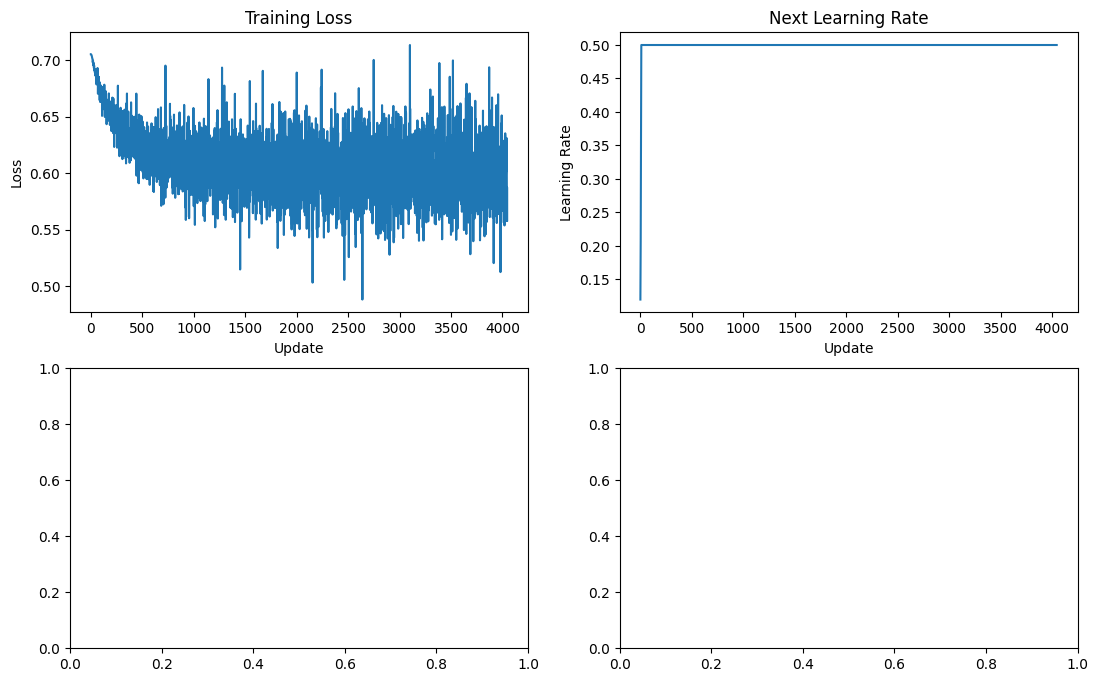

In [24]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Training loss
axes[0, 0].plot(logger_616.loss)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Update")
axes[0, 0].set_ylabel("Loss")

# Learning rate
axes[0, 1].plot(logger_616.lr_history)
axes[0, 1].set_title("Next Learning Rate")
axes[0, 1].set_xlabel("Update")
axes[0, 1].set_ylabel("Learning Rate")

# Gradient norms
axes[1, 0].plot(logger_616.grad_norm_history)
axes[1, 0].set_title("Gradient Norm")
axes[1, 0].set_xlabel("Update")
axes[1, 0].set_ylabel("Norm")

# Validation NDCG
axes[1, 1].plot(
    range(1, len(logger_616.ckpt_val_ndcg) + 1),
    logger_616.ckpt_val_ndcg,
    marker="o"
)
axes[1, 1].set_title("Validation NDCG@10")
axes[1, 1].set_xlabel("Checkpoint")
axes[1, 1].set_ylabel("NDCG@10")

plt.tight_layout()
plt.show()


print("Accepted updates:",
      sum(logger_616.improved_hist))

print("Rejected updates:",
      len(logger_616.improved_hist) - sum(logger_616.improved_hist))

print("Average line-search trials:",
      np.mean(logger_616.line_search_trials))

print("Maximum gradient norm:",
      max(logger_616.grad_norm_history))

print("Best NDCG@10:",
      best_616["val_ndcg"])
